In [1]:
from adjoint import *
import matplotlib.pyplot as plt
font = {"size": 26}

plt.rc("font", **font)
plt.rcParams["figure.figsize"] = (16, 9)
plt.rcParams["lines.linewidth"] = 3


In [2]:
f=0.05
ell=0
wl=1e-6
k0=2*np.pi/wl
fn=25
w0=f/(2*fn)
#w0=0.036
rmax=5*w0
nr=1000
zR=np.pi*w0**2/wl
wR=2/np.pi*fn*wl

zF=np.linspace(f-0.025,f+0.025,501)

nzf=len(zF)

steps=5000
fl=len(zF)//2
# assert(w0>wR),"Spot size is smaller than diffraction limited spot size"

In [3]:
[r,k] = DHTarrays(nr,rmax,ell)
[T_R2K,T_K2R] = DHTtransformMatrix(nr,rmax,ell)

In [4]:
phi_I=1j*np.exp(-(r/w0)**2)

ftest=np.linspace(0.045,0.055,11)
# get list of coefficients using create_initial_coeff
coeffs = [create_initial_coeff(rmax, 2*f) for f in ftest]
rho = r / rmax
Z_fit = calc_Z(rho)
Z_plus = calc_Z_plus(Z_fit)

zm_r=[generate_optic(c,Z_fit) for c in coeffs]
ftf_r=[forward_propagation(k,phi_I,T_R2K,T_K2R,zF,mr_r) for mr_r in zm_r]

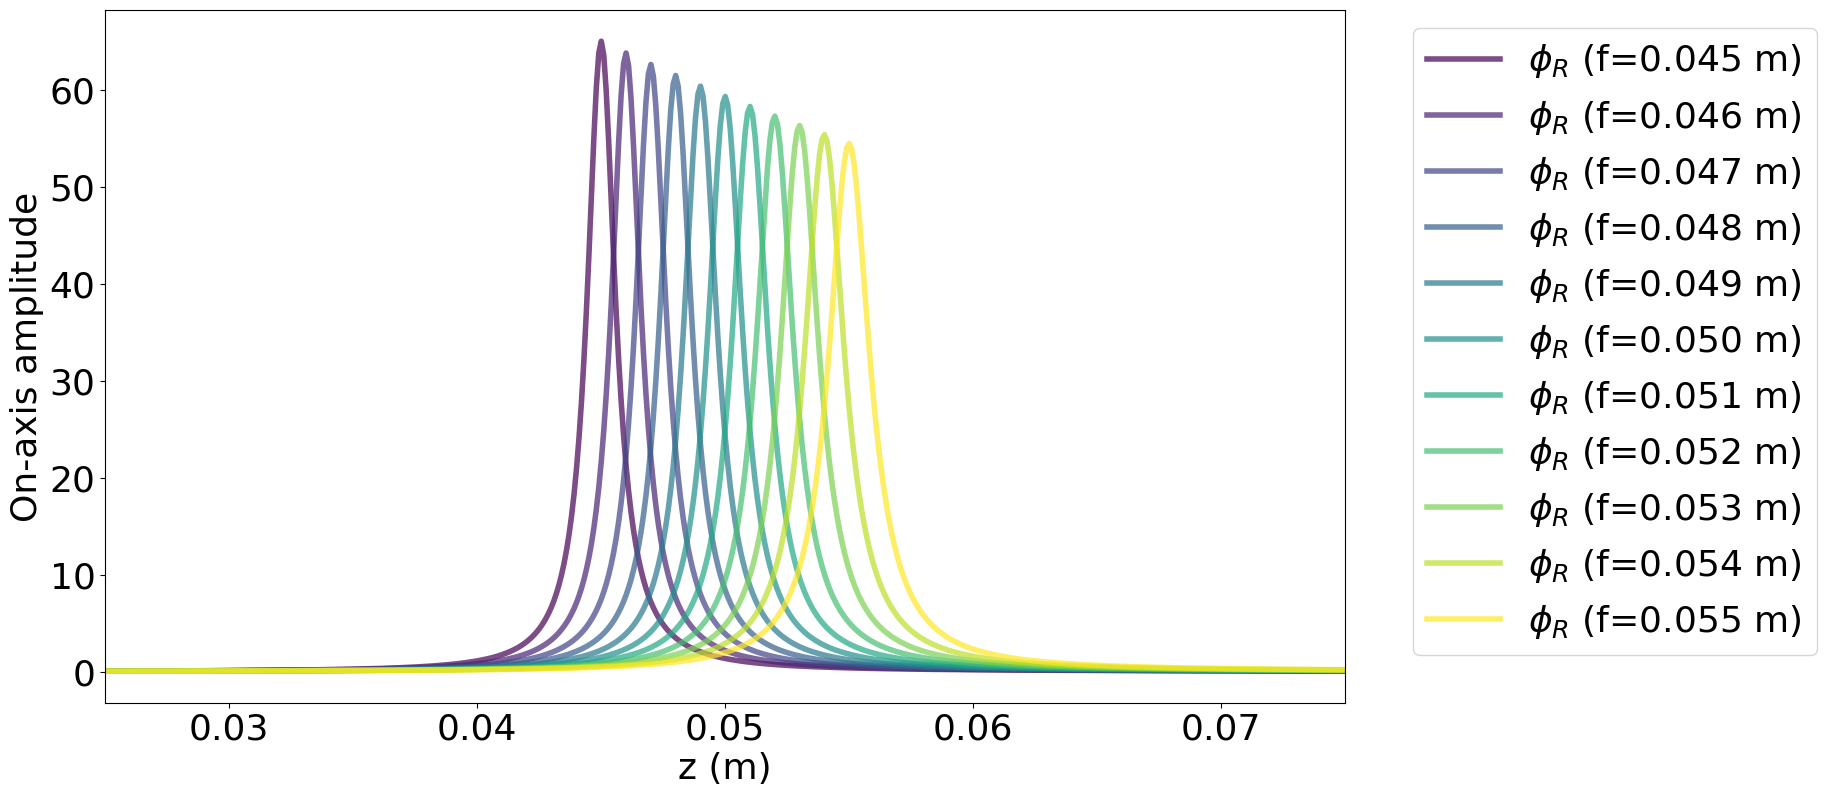

In [5]:
num_lines = len(ftf_r)

# Use the 'rainbow' colormap for line colors
line_colors = plt.cm.viridis(np.linspace(0, 1, num_lines))

for i, phr in enumerate(ftf_r):
    plt.plot(zF, np.real(ftf_r[i][0, :]), alpha=0.7, linewidth=4, label=r'$\phi_R$ (f=%.3f m)' % (ftest[i]), color=line_colors[i])

plt.xlim([f-0.025, f+0.025])
plt.ylabel('On-axis amplitude')
plt.xlabel('z (m)')
plt.legend(bbox_to_anchor=(1.04, 1), loc="upper left")
plt.savefig('test_zern2.png', bbox_inches='tight')
plt.show()
